<a href="https://colab.research.google.com/github/13rustam/Zhanakorgan_Agriculture/blob/main/Water_Crop_Use_Kaz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q --upgrade earthengine-api geemap xee matplotlib

import ee
import geemap
import matplotlib.pyplot as plt
import shapely.geometry
import xarray as xr
from xee import helpers



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 484.8/484.8 kB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 87.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.9/267.9 kB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 101.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.
google-genai 2.12.1 requires google-auth[requests]<2.56.0,>=2.48.1, but you have google-auth 2.62.0 which is incompatible.


In [3]:
# ----------------------------------------------------------------------
# Settings
# ----------------------------------------------------------------------
PROJECT = 'fifth-trainer-489105-c1'
RAYON_ASSET = f'projects/{PROJECT}/assets/Kazakhstan_Rayon_2023'
FIELDS_ASSET = f'projects/{PROJECT}/assets/Deliniated_Zhanakorgan_2023'

YEAR = 2025
MONTHS = range(2, 12)          # Feb-Nov: the months actually covered by data
MAX_CLOUD_PCT = 60             # scene-level pre-filter (cheap, saves compute)
PLOT_SCALE = 100               # metres; coarse grid for the facet plot (see notes)
NDVI_VIS = {'min': 0, 'max': 0.8,
            'palette': ['#a50026', '#f46d43', '#fee08b', '#a6d96a', '#1a9850', '#006837']}


In [4]:
# ----------------------------------------------------------------------
# 1. Authenticate / initialise
# ----------------------------------------------------------------------
# Note: the argument is `opt_url`, not `url`. The high-volume endpoint is meant
# for xee/bulk requests; if interactive map tiles feel slow, initialise with the
# default endpoint and only switch to high-volume before opening the xarray data.
try:
    ee.Initialize(project=PROJECT,
                  opt_url='https://earthengine-highvolume.googleapis.com')
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT,
                  opt_url='https://earthengine-highvolume.googleapis.com')

In [6]:
# ----------------------------------------------------------------------
# 2. Study area (whole district) and fields (overlay only)
# ----------------------------------------------------------------------
rayon = ee.FeatureCollection(RAYON_ASSET)
district = rayon.filter(ee.Filter.eq('ADM2_EN', 'Zhanakorgan District'))
roi = district.geometry()

fields = ee.FeatureCollection(FIELDS_ASSET)   # NOT used for NDVI, display only

print('District features found:', district.size().getInfo())   # should be 1

District features found: 1


In [7]:
# ----------------------------------------------------------------------
# 3. Sentinel-2 + cloud mask + NDVI
# ----------------------------------------------------------------------
def mask_s2(image):
    """Mask no-data, saturated, cloud shadow, clouds, cirrus and snow (SCL)."""
    scl = image.select('SCL')
    bad = scl.eq(0).Or(scl.eq(1)).Or(scl.eq(3)).Or(scl.gte(8).And(scl.lte(11)))
    return image.updateMask(bad.Not())


def add_ndvi(image):
    return image.addBands(image.normalizedDifference(['B8', 'B4']).rename('NDVI'))


s2_ndvi = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(roi)
    .filterDate(f'{YEAR}-01-01', f'{YEAR + 1}-01-01')
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', MAX_CLOUD_PCT))
    .map(mask_s2)
    .map(add_ndvi)
    .select('NDVI')
)

In [8]:
# ----------------------------------------------------------------------
# 4. Monthly max-NDVI composites (no reproject: keeps it lazy and fast)
# ----------------------------------------------------------------------
def monthly_composite(m):
    start = ee.Date.fromYMD(YEAR, m, 1)
    img = (
        s2_ndvi.filterDate(start, start.advance(1, 'month'))
        .max()
        .rename('NDVI')
        .clip(roi)
    )
    # system:time_start is what xee uses to build the time dimension
    return img.set({'month': m, 'system:time_start': start.millis()})


monthly = ee.ImageCollection.fromImages([monthly_composite(m) for m in MONTHS])

Generating monthly NDVI facet plot...


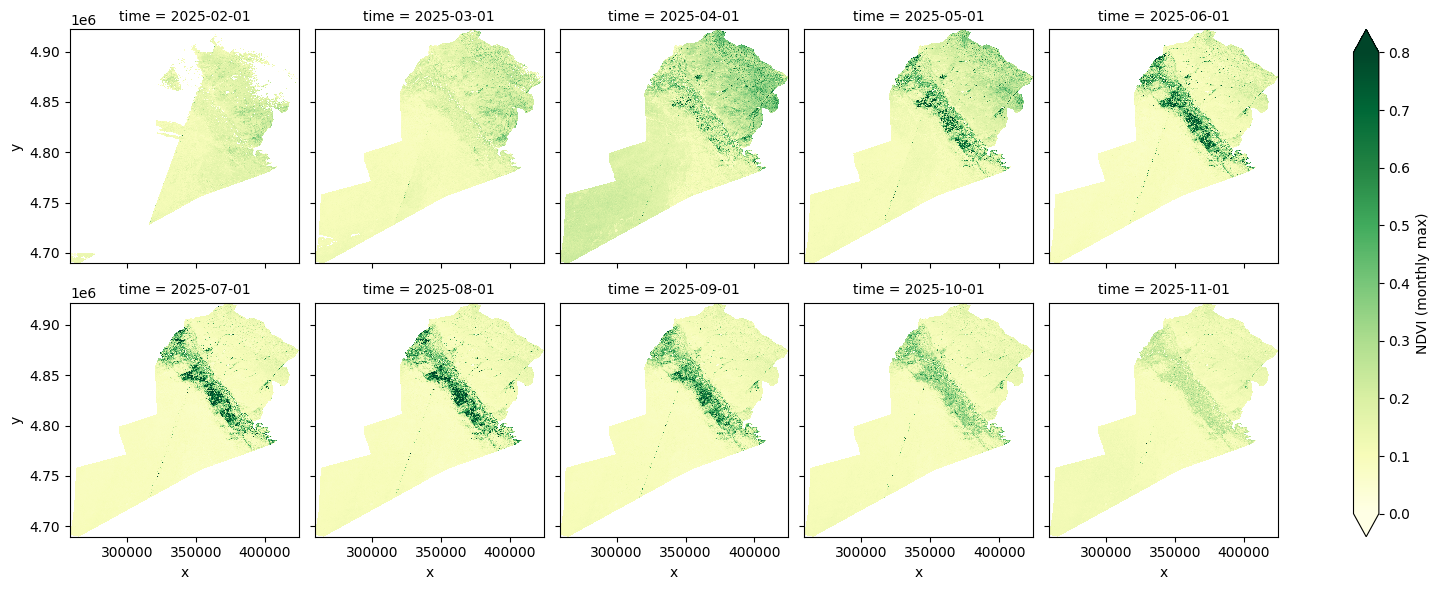

In [9]:
# ----------------------------------------------------------------------
# 5. Facet plot via xarray (coarse grid; native 10 m would be ~10x10 times larger)
# ----------------------------------------------------------------------
shapely_geom = shapely.geometry.shape(roi.simplify(100).getInfo())

grid = helpers.fit_geometry(
    geometry=shapely_geom,
    geometry_crs='EPSG:4326',
    grid_crs='EPSG:32642',
    grid_scale=(PLOT_SCALE, -PLOT_SCALE),
)
ds = xr.open_dataset(monthly, engine='ee', **grid)

print('Generating monthly NDVI facet plot...')
ds['NDVI'].plot(
    col='time', col_wrap=5, cmap='YlGn', vmin=0, vmax=0.8,
    cbar_kwargs={'label': 'NDVI (monthly max)'},
)
plt.show()

Generating classified NDVI multi-panel plot...


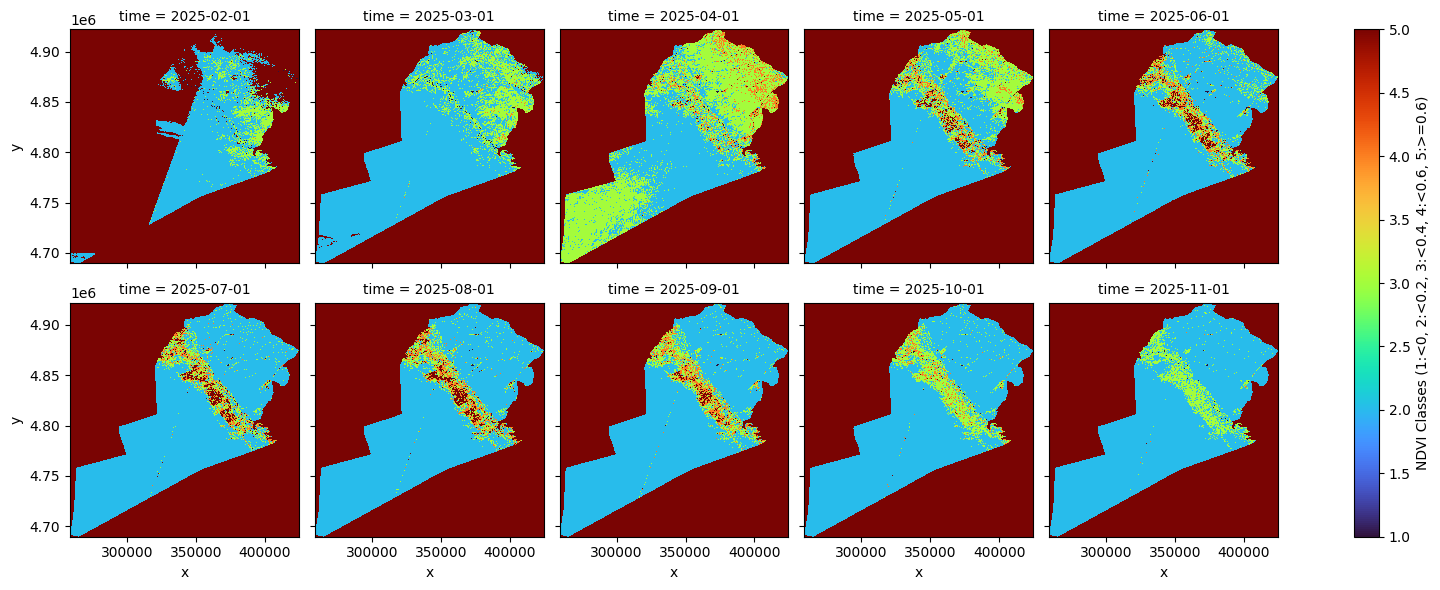

In [10]:
# ----------------------------------------------------------------------
# 5b. Simple NDVI-based Land Cover / Class Proxy using Xarray
# ----------------------------------------------------------------------
ndvi_monthly = ds['NDVI']

ndvi_classes = xr.where(
    ndvi_monthly < 0,
    1,
    xr.where(
        ndvi_monthly < 0.2,
        2,
        xr.where(
            ndvi_monthly < 0.4,
            3,
            xr.where(ndvi_monthly < 0.6, 4, 5),
        ),
    ),
)

# Store it back into the dataset for convenience
ds['ndvi_classes'] = ndvi_classes

print('Generating classified NDVI multi-panel plot...')
ds['ndvi_classes'].plot(
    col='time',
    col_wrap=5,
    cmap='turbo',
    vmin=1,
    vmax=5,
    cbar_kwargs={
        'label': 'NDVI Classes (1:<0, 2:<0.2, 3:<0.4, 4:<0.6, 5:>=0.6)'
    },
)
plt.show()

Generating NDVI anomaly multi-panel plot...


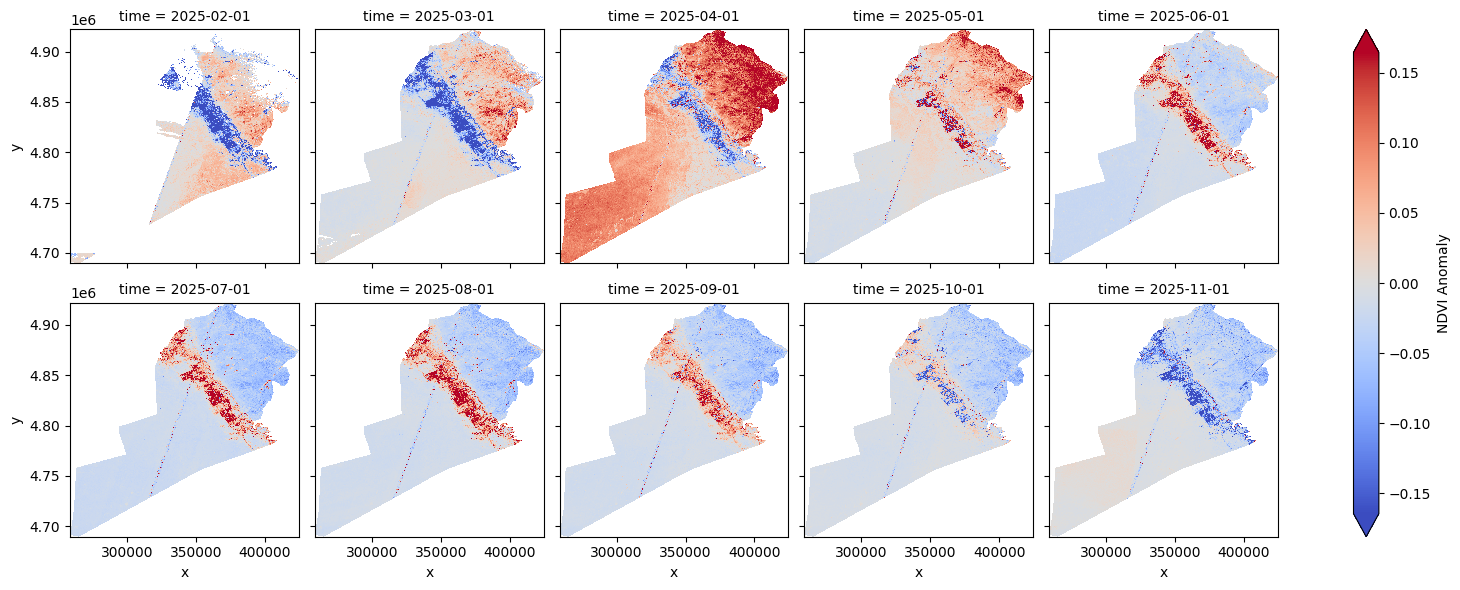

In [11]:
# ----------------------------------------------------------------------
# 5c. NDVI Anomaly and Temporal Difference via Xarray
# ----------------------------------------------------------------------
ndvi_monthly = ds['NDVI']

# 1. NDVI Anomaly (Deviation from the seasonal mean)
ndvi_anomaly = ndvi_monthly - ndvi_monthly.mean('time')
ds['ndvi_anomaly'] = ndvi_anomaly

print('Generating NDVI anomaly multi-panel plot...')
ds['ndvi_anomaly'].plot(
    col='time',
    col_wrap=5,
    cmap='coolwarm',  # Diverging colormap: blue = negative anomaly, red = positive anomaly
    robust=True,
    cbar_kwargs={'label': 'NDVI Anomaly'},
)
plt.show()

Generating NDVI temporal difference multi-panel plot...


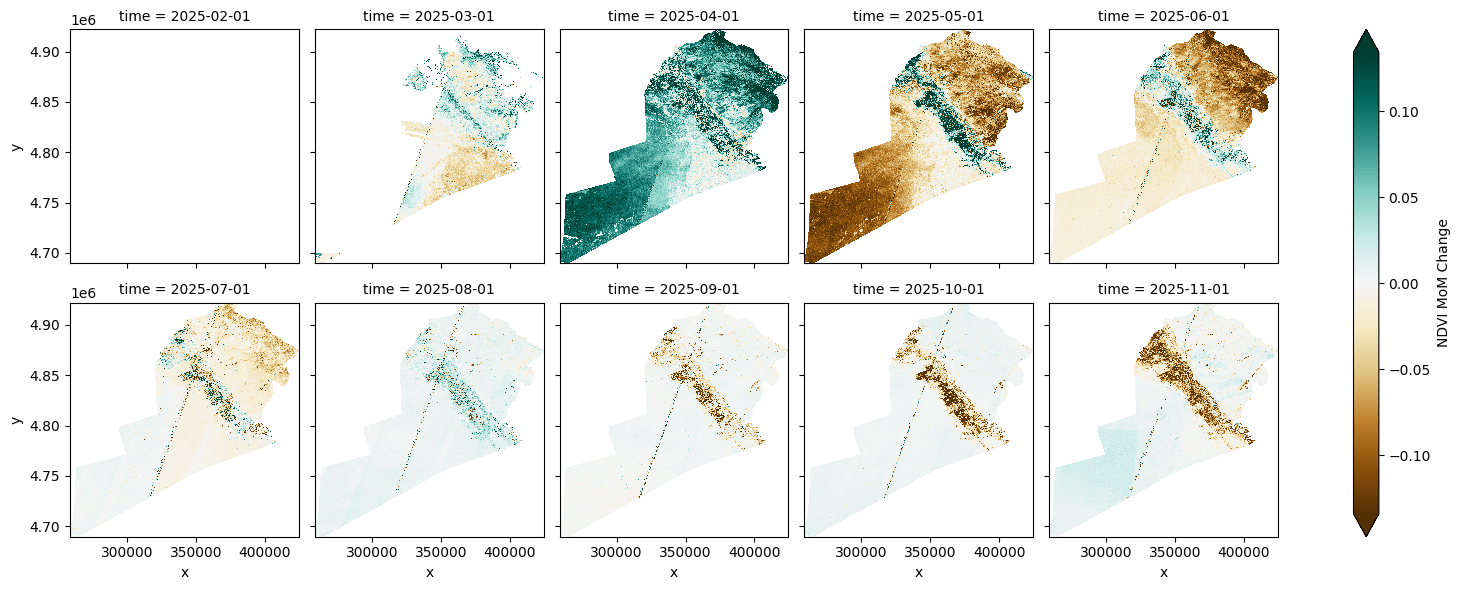

In [12]:
# 2. NDVI Temporal Difference (Month-over-month change)
ndvi_diff = ndvi_monthly.diff('time')
ds['ndvi_diff'] = ndvi_diff

print('Generating NDVI temporal difference multi-panel plot...')
ds['ndvi_diff'].plot(
    col='time',
    col_wrap=5,
    cmap='BrBG',  # Brown/Green diverging colormap: brown = decrease, green = increase
    robust=True,
    cbar_kwargs={'label': 'NDVI MoM Change'},
)
plt.show()

Cluster distribution: (array([0, 1, 2, 3], dtype=int32), array([1160940,   73147,  327508,  117119]))
Generating crop clustering map...


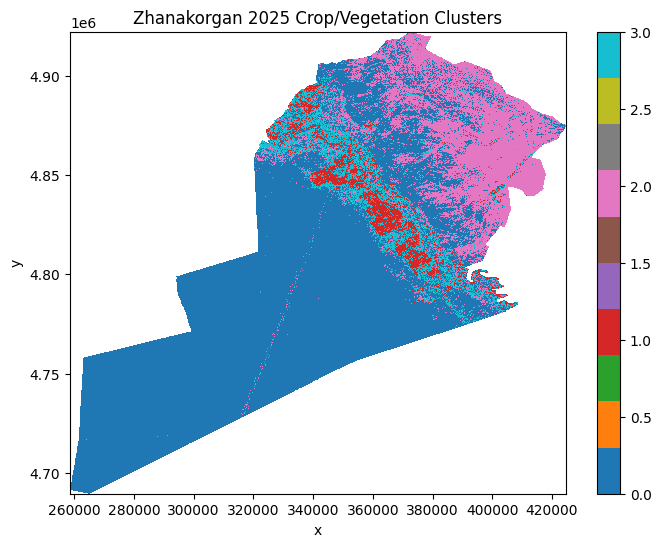

In [14]:
# ----------------------------------------------------------------------
# 5d. Crop Clustering via KMeans on Monthly NDVI Time-Series
# ----------------------------------------------------------------------
import warnings
import numpy as np
from sklearn.cluster import KMeans

warnings.filterwarnings('ignore', category=RuntimeWarning)

# 1. Use the monthly NDVI dataset from your pipeline
ndvi_monthly = ds['NDVI']

# 2. Interpolate and fill any missing gaps across the time dimension
ndvi_interp = ndvi_monthly.interpolate_na(dim='time', method='linear')
ndvi_interp = ndvi_interp.ffill(dim='time').bfill(dim='time')

# 3. Stack spatial dimensions (y, x) into a single pixel dimension for scikit-learn
ndvi_stack = ndvi_interp.stack(pixel=['y', 'x']).transpose('pixel', 'time')
ndvi_arr = ndvi_stack.to_numpy()

# 4. Filter out pixels with any NaNs (areas outside the district boundary)
valid = np.isfinite(ndvi_arr).all(axis=1)

# 5. Run KMeans Clustering
model = KMeans(n_clusters=4, random_state=42, n_init=10)
label = model.fit_predict(ndvi_arr[valid])

# 6. Reconstruct the full spatial grid
all_labels = np.full(ndvi_stack.sizes['pixel'], np.nan)
all_labels[valid] = label

# Unstack back to 2D spatial grid (y, x)
xr_label = xr.DataArray(
    all_labels, dims=['pixel'], coords={'pixel': ndvi_stack.pixel}
).unstack('pixel')

# Print cluster pixel distribution counts
print('Cluster distribution:', np.unique(label, return_counts=True))

# 7. Plot the cluster map
print('Generating crop clustering map...')
plt.figure(figsize=(8, 6))
xr_label.plot(vmin=0, vmax=3, cmap='tab10')
plt.title('Zhanakorgan 2025 Crop/Vegetation Clusters')
plt.show()

Peak Season Cluster distribution: (array([0, 1, 2, 3], dtype=int32), array([ 178604,   94414,   50578, 1355118]))
Generating peak-season crop clustering map...


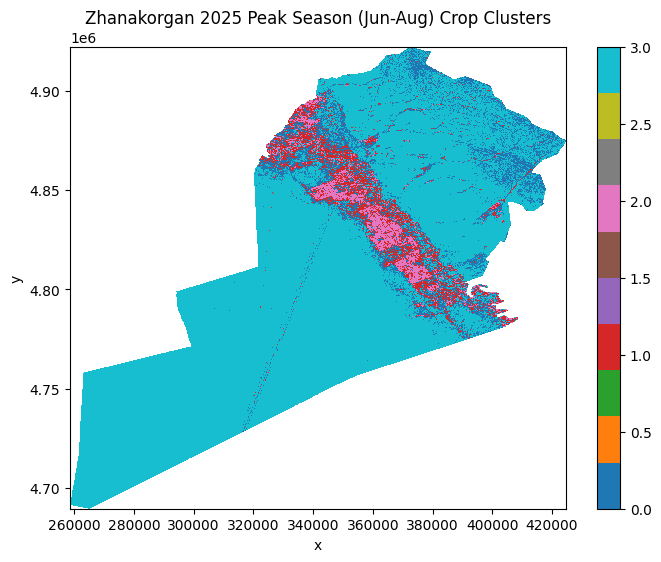

In [16]:
# ----------------------------------------------------------------------
# 5d. Crop Clustering via KMeans (Filtered for Peak Months: June, July, Aug)
# ----------------------------------------------------------------------
import warnings
import numpy as np
from sklearn.cluster import KMeans

warnings.filterwarnings('ignore', category=RuntimeWarning)

# 1. Select only months 6, 7, and 8 from your monthly NDVI dataset
ndvi_monthly = ds['NDVI']
ndvi_peak = ndvi_monthly.sel(time=ndvi_monthly.time.dt.month.isin([6, 7, 8]))

# 2. Interpolate and fill any missing gaps across the peak time steps
ndvi_interp = ndvi_peak.interpolate_na(dim='time', method='linear')
ndvi_interp = ndvi_interp.ffill(dim='time').bfill(dim='time')

# 3. Stack spatial dimensions (y, x) into a single pixel dimension for scikit-learn
ndvi_stack = ndvi_interp.stack(pixel=['y', 'x']).transpose('pixel', 'time')
ndvi_arr = ndvi_stack.to_numpy()

# 4. Filter out pixels with any NaNs (areas outside the district boundary)
valid = np.isfinite(ndvi_arr).all(axis=1)

# 5. Run KMeans Clustering on peak season profiles
model = KMeans(n_clusters=4, random_state=42, n_init=10)
label = model.fit_predict(ndvi_arr[valid])

# 6. Reconstruct the full spatial grid
all_labels = np.full(ndvi_stack.sizes['pixel'], np.nan)
all_labels[valid] = label

# Unstack back to 2D spatial grid (y, x)
xr_label = xr.DataArray(
    all_labels, dims=['pixel'], coords={'pixel': ndvi_stack.pixel}
).unstack('pixel')

# Print cluster pixel distribution counts
print(
    'Peak Season Cluster distribution:', np.unique(label, return_counts=True)
)

# 7. Plot the cluster map
print('Generating peak-season crop clustering map...')
plt.figure(figsize=(8, 6))
xr_label.plot(vmin=0, vmax=3, cmap='tab10')
plt.title('Zhanakorgan 2025 Peak Season (Jun-Aug) Crop Clusters')
plt.show()

Generating peak-season binary crop mask facet plot...


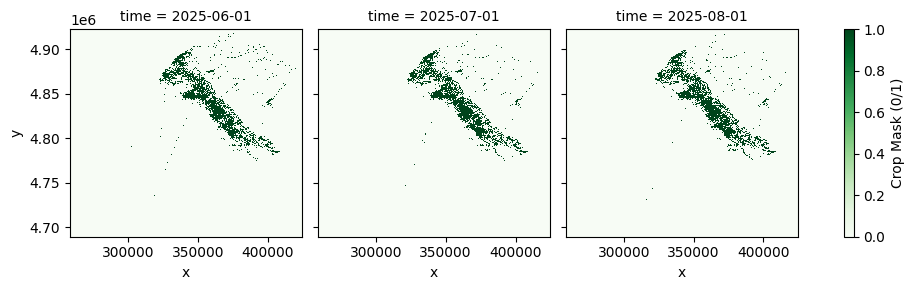

            crop_area_km2
time                     
2025-06-01        1487.67
2025-07-01        1455.01
2025-08-01        1503.68


In [21]:
# ----------------------------------------------------------------------
# 5e. Otsu Thresholding and Crop Area Calculation (Peak Months: Jun-Aug)
# ----------------------------------------------------------------------
import numpy as np
from skimage.filters import threshold_otsu

# 1. Select only months 6, 7, and 8 from your monthly NDVI dataset
ndvi_monthly = ds['NDVI']
ndvi_peak = ndvi_monthly.sel(time=ndvi_monthly.time.dt.month.isin([6, 7, 8]))

# 2. Calculate Otsu threshold per time step safely (ignoring NaN boundaries)
thr_list = []
for i in ndvi_peak.time.values:
  img_sel = ndvi_peak.sel(time=i).values
  valid_vals = img_sel[np.isfinite(img_sel)]  # Filter out district NaNs

  if valid_vals.size > 0:
    thr_sel = threshold_otsu(valid_vals)
  else:
    thr_sel = 0.3  # Fallback default if a slice is empty
  thr_list.append(thr_sel)

# Create an Xarray DataArray for the time-varying thresholds
thr_xr = xr.DataArray(
    thr_list, dims=['time'], coords={'time': ndvi_peak.time.values}
)

# 3. Generate binary crop layer using dynamic Otsu thresholds
crop_layer = (ndvi_peak >= thr_xr).astype(int)

# Plot the binary crop maps over peak months
print('Generating peak-season binary crop mask facet plot...')
crop_layer.plot(
    col='time',
    col_wrap=3,
    cmap='Greens',
    cbar_kwargs={'label': 'Crop Mask (0/1)'},
)
plt.show()

# 4. Calculate Crop Area over peak months
# Note: PLOT_SCALE is 100 meters, so each pixel is 100m x 100m = 10,000 m² (0.01 km²)
pixel_resolution_m = 100
pixel_area_km2 = (pixel_resolution_m * pixel_resolution_m) / 1e6

crop_pixels = (crop_layer == 1).sum(dim=['x', 'y'])
crop_area = crop_pixels * pixel_area_km2



# Print final peak season summary table
print(crop_area.to_dataframe('crop_area_km2'))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 401.7/401.7 kB 16.9 MB/s eta 0:00:00
Running TimeSeriesKMeans clustering on NDVI trajectories...
Plotting cluster spatial distribution...


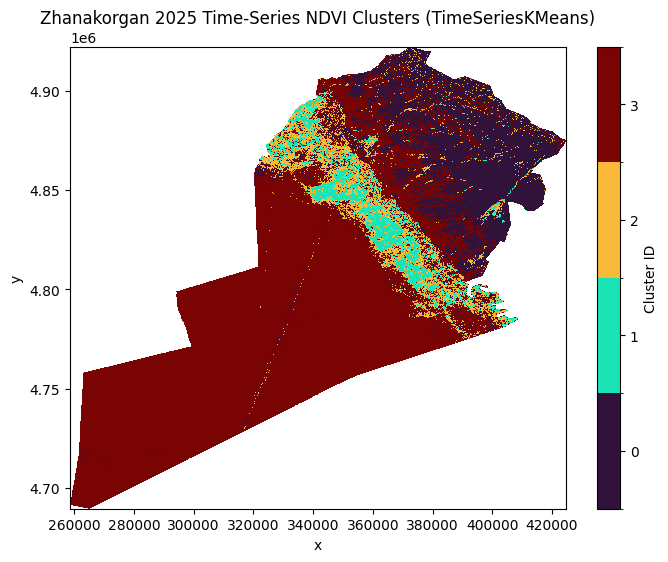

,date,cluster_0,cluster_1,cluster_2,cluster_3
0,2025-02-01,0.212913,0.185699,0.184253,0.119170
1,2025-03-01,0.225460,0.197072,0.195142,0.114311
2,2025-04-01,0.321081,0.360013,0.275775,0.177600
3,2025-05-01,0.239803,0.523336,0.305681,0.117125
4,2025-06-01,0.152834,0.594885,0.319670,0.095995


Plotting cluster temporal trajectories...


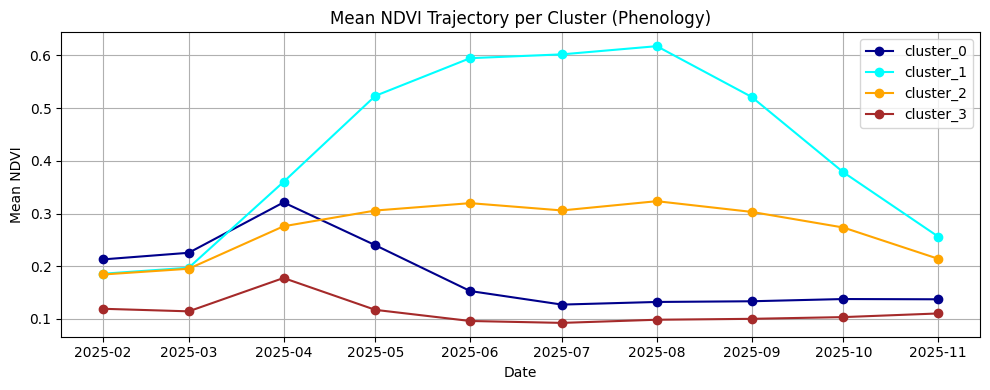

In [22]:
# ----------------------------------------------------------------------
# 5f. Unsupervised Time-Series Clustering (TimeSeriesKMeans via tslearn)
# ----------------------------------------------------------------------
# Install tslearn if not already present
!pip install -q tslearn

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from tslearn.clustering import TimeSeriesKMeans

# 1. Prepare smoothed/interpolated monthly NDVI time series
ndvi_monthly = ds['NDVI']
ndvi_smooth = ndvi_monthly.interpolate_na(dim='time', method='linear')
ndvi_smooth = ndvi_smooth.ffill(dim='time').bfill(dim='time')

# 2. Stack into pixel-time format
ndvi_stack = ndvi_smooth.stack(pixel=['y', 'x']).transpose('pixel', 'time')

# Filter out pixels with any missing values across the time-series
valid = np.isfinite(ndvi_stack.values).all(axis=1)

# 3. Run TimeSeriesKMeans Clustering
print('Running TimeSeriesKMeans clustering on NDVI trajectories...')
model = TimeSeriesKMeans(
    n_clusters=4, random_state=42, metric='euclidean', max_iter=10
)
labels = model.fit_predict(ndvi_stack[valid].values)

# 4. Reconstruct spatial grid from cluster labels
classified = xr.DataArray(
    labels, dims='pixel', coords={'pixel': ndvi_stack[valid].pixel}
).unstack('pixel')

# Plot the spatial cluster map
print('Plotting cluster spatial distribution...')
plt.figure(figsize=(8, 6))
classified.plot(
    cmap='turbo',
    levels=np.arange(-0.5, 4, 1),
    cbar_kwargs={'ticks': range(4), 'label': 'Cluster ID'},
)
plt.title('Zhanakorgan 2025 Time-Series NDVI Clusters (TimeSeriesKMeans)')
plt.show()

# 5. Build DataFrame for cluster trajectory analysis
df = pd.DataFrame({'date': ndvi_stack.time.values})
valid_ndvi_arr = ndvi_stack.values[valid]

for i in np.unique(labels):
  cluster_mean = valid_ndvi_arr[labels == i].mean(axis=0)
  df[f'cluster_{i}'] = cluster_mean

# Display the trajectory table
display(df.head())

# 6. Plot cluster temporal profiles (Phenological curves)
print('Plotting cluster temporal trajectories...')
fig, ax = plt.subplots(figsize=(10, 4))
colors = ['darkblue', 'cyan', 'orange', 'brown']

for i in range(4):
  col_name = f'cluster_{i}'
  if col_name in df.columns:
    ax.plot(
        df['date'],
        df[col_name],
        marker='o',
        label=col_name,
        color=colors[i % len(colors)],
    )

ax.set_title('Mean NDVI Trajectory per Cluster (Phenology)')
ax.set_xlabel('Date')
ax.set_ylabel('Mean NDVI')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

Generating SLIC segmentation comparison plot...


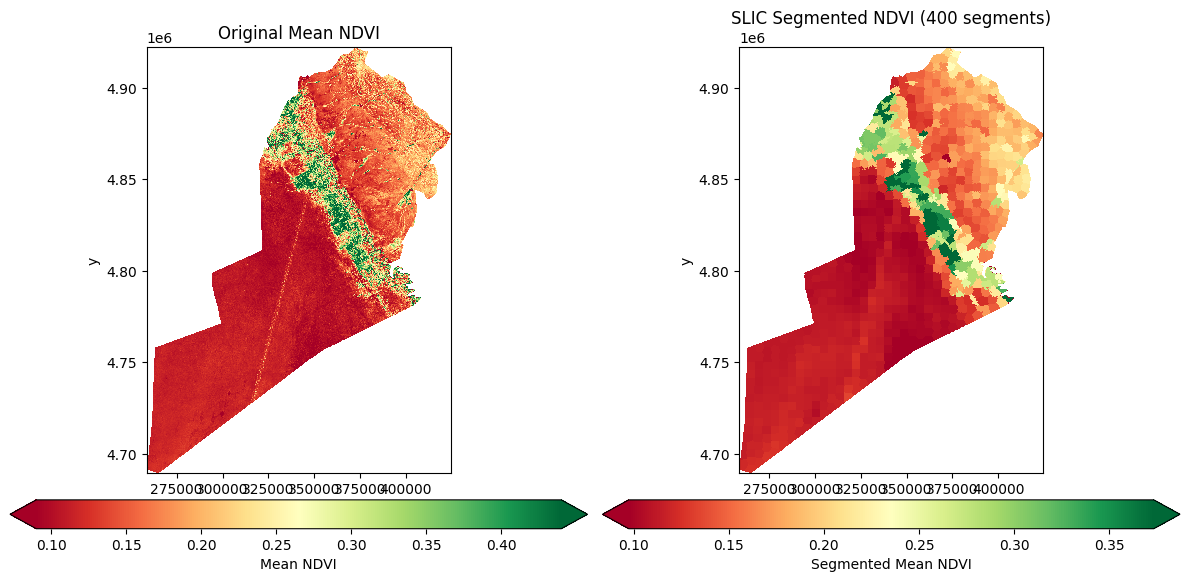

Successfully saved segmentation figure to ndvi_segment.png!


In [25]:
# ----------------------------------------------------------------------
# 5g. SLIC Superpixel Segmentation on Mean NDVI
# ----------------------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from scipy.ndimage import mean as ndimage_mean
from skimage.segmentation import slic

# 1. Generate 2D mean NDVI across the time dimension
ndvi_mean = ds['NDVI'].mean('time')

# Extract values and create a valid mask for district boundaries (handling NaNs)
ndvi_vals = ndvi_mean.values
mask = np.isfinite(ndvi_vals)
ndvi_filled = np.nan_to_num(ndvi_vals, nan=0.0)

# 2. Run SLIC Superpixel Segmentation
ndvi_segment = slic(
    image=ndvi_filled,
    n_segments=2000,
    compactness=0.1,
    start_label=1,
    channel_axis=None,
)

# Restrict segments strictly inside the district boundary mask
ndvi_segment = np.where(mask, ndvi_segment, 0)

# 3. Calculate mean NDVI per segment using scipy
valid_indices = np.unique(ndvi_segment[ndvi_segment > 0])
ndvi_seg_mean_vals = ndimage_mean(
    input=ndvi_vals, labels=ndvi_segment, index=valid_indices
)

# Map segment means back to a full 2D grid with NaNs outside
ndvi_seg_mean_full = np.full_like(ndvi_vals, np.nan, dtype=float)
for idx, mean_val in zip(valid_indices, ndvi_seg_mean_vals):
  ndvi_seg_mean_full[ndvi_segment == idx] = mean_val

# 4. Create Xarray DataArray for the segmented result
result = xr.DataArray(
    ndvi_seg_mean_full, dims=ndvi_mean.dims, coords=ndvi_mean.coords
)

# 5. Side-by-Side Plotting and Export
print('Generating SLIC segmentation comparison plot...')
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ndvi_mean.plot(
    ax=ax[0],
    robust=True,
    cmap='RdYlGn',
    cbar_kwargs={'orientation': 'horizontal', 'pad': 0.05, 'label': 'Mean NDVI'},
)
ax[0].set_title('Original Mean NDVI')

result.plot(
    ax=ax[1],
    robust=True,
    cmap='RdYlGn',
    cbar_kwargs={
        'orientation': 'horizontal',
        'pad': 0.05,
        'label': 'Segmented Mean NDVI',
    },
)
ax[1].set_title('SLIC Segmented NDVI (400 segments)')

for i in ax:
  i.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.savefig('ndvi_segment.png', dpi=360, bbox_inches='tight')
plt.show()

print('Successfully saved segmentation figure to ndvi_segment.png!')

Generating Felzenszwalb segmentation comparison plot...


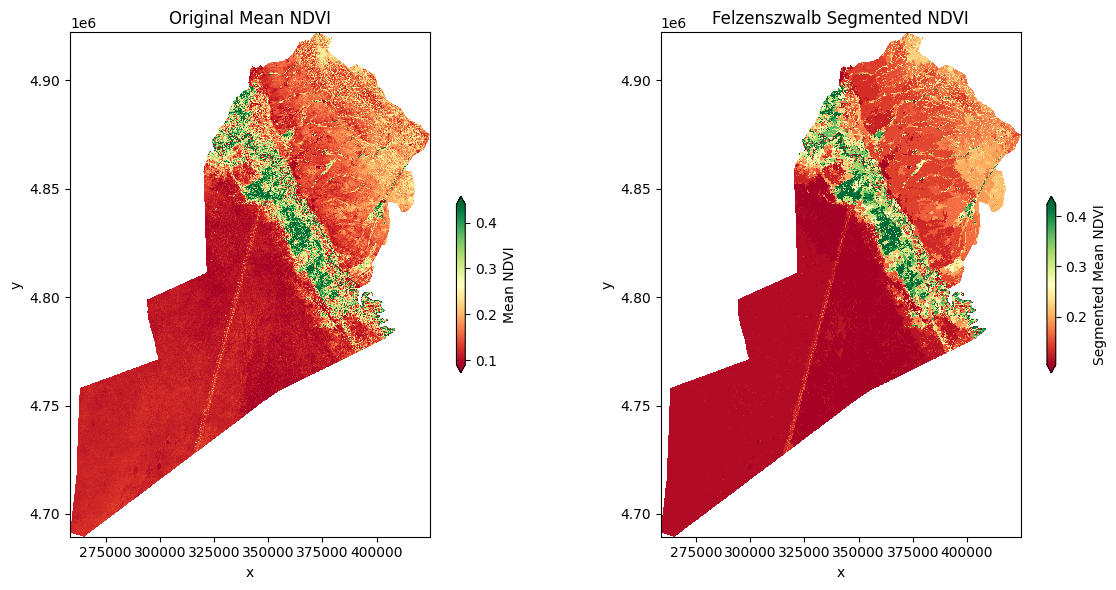

Successfully saved Felzenszwalb segmentation figure to ndvi_seg.png!


In [26]:
# ----------------------------------------------------------------------
# 5h. Felzenszwalb Graph-Based Segmentation on Mean NDVI
# ----------------------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from scipy.ndimage import mean as ndimage_mean
from skimage.segmentation import felzenszwalb

# 1. Get mean NDVI across time from your dataset
ndvi_mean = ds['NDVI'].mean('time')

# Extract values and build a valid district mask to handle NaNs
ndvi_vals = ndvi_mean.values
mask = np.isfinite(ndvi_vals)
ndvi_filled = np.nan_to_num(ndvi_vals, nan=0.0)

# 2. Run Felzenszwalb Segmentation
labels = felzenszwalb(
    image=ndvi_filled, scale=50, sigma=0.1, min_size=5, channel_axis=None
)

# Restrict segments strictly inside the district boundary mask
labels = np.where(mask, labels, 0)

# 3. Calculate mean NDVI per segment safely using scipy
valid_indices = np.unique(labels[labels > 0])
ndvi_seg_mean_vals = ndimage_mean(
    input=ndvi_vals, labels=labels, index=valid_indices
)

# Map segment means back to a full 2D grid with NaNs outside
ndvi_seg_mean_full = np.full_like(ndvi_vals, np.nan, dtype=float)
for idx, mean_val in zip(valid_indices, ndvi_seg_mean_vals):
  ndvi_seg_mean_full[labels == idx] = mean_val

# Create Xarray DataArray for the segmented result
ndvi_mean_seg = xr.DataArray(
    ndvi_seg_mean_full, dims=ndvi_mean.dims, coords=ndvi_mean.coords
)

# 4. Side-by-Side Plotting and Export
print('Generating Felzenszwalb segmentation comparison plot...')
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ndvi_mean.plot(
    ax=ax[0],
    robust=True,
    cmap='RdYlGn',
    cbar_kwargs={'shrink': 0.35, 'label': 'Mean NDVI'},
)
ax[0].set_title('Original Mean NDVI')

ndvi_mean_seg.plot(
    ax=ax[1],
    robust=True,
    cmap='RdYlGn',
    cbar_kwargs={'shrink': 0.35, 'label': 'Segmented Mean NDVI'},
)
ax[1].set_title('Felzenszwalb Segmented NDVI')

for a in ax:
  a.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.savefig('ndvi_seg.png', dpi=360, bbox_inches='tight')
plt.show()

print('Successfully saved Felzenszwalb segmentation figure to ndvi_seg.png!')